# 02 · Fingerprint a corpus
[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/rusparrish/visual-thinking-lens/blob/main/notebooks/02_fingerprint_a_corpus.ipynb)

Point this at a folder of images from one engine, one artist, or one prompt set. The fingerprint describes how that maker occupies structural space.

> **Authorship is variance. Priors are clustering.**

In [1]:
# Works locally (pip install -e .) or in Colab.
try:
    import vtl
except ImportError:
    %pip install -q git+https://github.com/rusparrish/visual-thinking-lens
    import vtl
from pathlib import Path
IMAGES = Path("../examples/images") if Path("../examples/images").exists() else None
if IMAGES is None:  # Colab: fetch the sample images
    !git clone -q --depth 1 https://github.com/rusparrish/visual-thinking-lens /content/vtl-repo
    IMAGES = Path("/content/vtl-repo/examples/images")
print("vtl", vtl.__version__, "| images:", IMAGES)

vtl 0.1.0 | images: ../examples/images


In [2]:
df = vtl.measure_many(IMAGES)   # or vtl.measure_many("path/to/your/folder")
df[["filename", *vtl.KERNEL_KEYS, "mask_mode"]].round(3)

,filename,delta_x,delta_y,r_v,rho_r,mu,x_p,theta,d_s,sdi,mask_mode
0,abstract.jpg,0.049,0.107,0.961,12.108,0.045,0.742,0.035,0.002,0.291,TEXTURE_FIELD
1,collapse.jpg,-0.105,0.035,0.897,12.023,0.008,0.365,0.029,0.001,0.224,TEXTURE_FIELD
2,drawing.jpg,0.032,0.172,0.718,12.175,0.005,0.528,0.004,0.002,0.266,TEXTURE_FIELD
3,frog.jpg,0.009,-0.187,0.730,14.555,0.383,0.389,0.000,0.002,0.184,REGION_FIELD
4,landscape.jpg,0.004,0.034,0.825,14.344,0.151,0.328,0.018,0.002,0.219,TEXTURE_FIELD
5,portrait.jpg,0.060,-0.116,0.938,13.287,0.114,0.369,0.014,0.003,0.191,TEXTURE_FIELD
6,room.jpg,0.054,0.059,0.911,13.702,0.265,0.301,0.009,0.003,0.210,REGION_FIELD
7,still_life.jpg,-0.038,0.037,0.912,15.005,0.067,0.340,0.005,0.002,0.213,TEXTURE_FIELD
8,study.jpg,-0.043,0.005,0.965,12.215,0.007,0.432,0.008,0.002,0.230,TEXTURE_FIELD
9,walking.jpg,0.005,-0.064,0.818,12.044,0.006,0.478,0.006,0.002,0.261,TEXTURE_FIELD


### The fingerprint
- **window_width** (p90 − p10): the operating range on each axis. Prefer this for signed metrics like `delta_x`.
- **spread**: CV = std/|mean| (tight / moderate / wide). Signed offsets like `delta_x` read `signed: see window`, because CV means nothing when the mean sits at zero.
- **walls**: *hard* = rarely leaves a narrow band; *soft* = wanders.
- **bimodal**: flat distribution, maybe two discrete modes.

In [3]:
vtl.fingerprint(df).round(3)

,n,mean,std,cv,spread,p10,p50,p90,window_width,wall_hardness,walls,skew,kurtosis,bimodal
metric,,,,,,,,,,,,,,
delta_x,10,0.002,0.049,NaN,signed: see window,-0.049,0.007,0.054,0.103,0.299,moderate,-0.800,2.783,False
delta_y,10,0.008,0.100,NaN,signed: see window,-0.123,0.035,0.114,0.237,0.279,moderate,-0.415,2.530,False
r_v,10,0.868,0.086,0.099,tight,0.729,0.904,0.961,0.232,0.347,soft,-0.611,1.972,True
rho_r,10,13.146,1.121,0.085,tight,12.042,12.751,14.600,2.559,0.376,soft,0.392,1.514,True
mu,10,0.105,0.122,1.161,wide,0.006,0.056,0.276,0.271,0.323,soft,1.185,3.164,False
x_p,10,0.427,0.124,0.291,moderate,0.326,0.379,0.550,0.224,0.281,moderate,1.476,4.372,False
theta,10,0.013,0.011,0.838,wide,0.003,0.009,0.029,0.026,0.308,soft,0.935,2.632,False
d_s,10,0.002,0.000,0.176,moderate,0.002,0.002,0.003,0.001,0.315,soft,-0.766,2.497,False
sdi,10,0.229,0.032,0.141,tight,0.190,0.222,0.269,0.079,0.303,soft,0.497,2.203,False


### Where the mass lands
Every point is one image's mass centroid in the frame. A tight cluster at the center across varied subjects is the signature of a learned spatial prior.

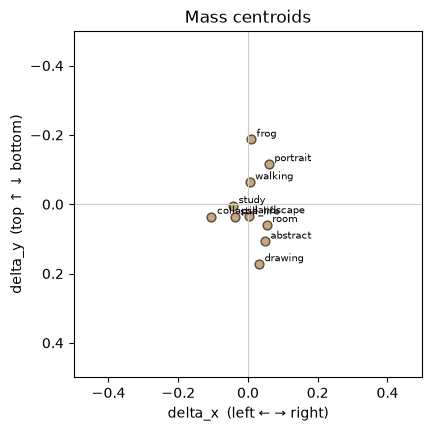

In [4]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.axhline(0, color="#ccc", lw=.8); ax.axvline(0, color="#ccc", lw=.8)
ax.scatter(df.delta_x, df.delta_y, s=40, color="#c4a882", edgecolor="#5a4a35")
for _, r in df.iterrows():
    ax.annotate(r.filename.split(".")[0], (r.delta_x, r.delta_y), fontsize=7, xytext=(4, 2), textcoords="offset points")
ax.set_xlim(-.5, .5); ax.set_ylim(-.5, .5); ax.invert_yaxis()   # image convention: negative = upper frame
ax.set_xlabel("delta_x  (left ← → right)"); ax.set_ylabel("delta_y  (top ↑ ↓ bottom)")
ax.set_title("Mass centroids"); plt.show()

### Do prompts move it? (creative rigidity)
With several images per prompt, compare how much different prompts vary vs re-rolls of the same prompt. Ratio ≈ 1: the prompt barely matters. Ratio > 2.5: prompts drive structure.

```python
table, overall = vtl.rigidity(df, vtl.midjourney_prompt)   # MidJourney filenames
table, overall = vtl.rigidity(df, "prompt")               # or any column you add
```

### Compare two makers
```python
a = vtl.measure_many("engine_a/"); b = vtl.measure_many("engine_b/")
vtl.compare(a, b, labels=("A", "B"))
```
Post what you find in [Discussions](https://github.com/rusparrish/visual-thinking-lens/discussions); fingerprints from engines we haven't measured are especially welcome.